In [79]:
import pandas as pd
import numpy as np

In [52]:
df = pd.read_csv("../data/winequality-white.csv", sep=';')

In [29]:
df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6
1,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6
2,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6
3,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6
4,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6


In [30]:
df.shape

(4898, 12)

In [31]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4898 entries, 0 to 4897
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         4898 non-null   float64
 1   volatile acidity      4898 non-null   float64
 2   citric acid           4898 non-null   float64
 3   residual sugar        4898 non-null   float64
 4   chlorides             4898 non-null   float64
 5   free sulfur dioxide   4898 non-null   float64
 6   total sulfur dioxide  4898 non-null   float64
 7   density               4898 non-null   float64
 8   pH                    4898 non-null   float64
 9   sulphates             4898 non-null   float64
 10  alcohol               4898 non-null   float64
 11  quality               4898 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 459.3 KB


In [32]:
df.isnull().sum()

fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

In [33]:
df.duplicated().sum()

np.int64(937)

In [34]:
df.describe()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000
mean,6.854788,0.278241,0.334192,6.391415,0.045772,35.308085,138.360657,0.994027,3.188267,0.489847,10.514267,5.877909
std,0.843868,0.100795,0.121020,5.072058,0.021848,17.007137,42.498065,0.002991,0.151001,0.114126,1.230621,0.885639
min,3.800000,0.080000,0.000000,0.600000,0.009000,2.000000,9.000000,0.987110,2.720000,0.220000,8.000000,3.000000
25%,6.300000,0.210000,0.270000,1.700000,0.036000,23.000000,108.000000,0.991723,3.090000,0.410000,9.500000,5.000000
50%,6.800000,0.260000,0.320000,5.200000,0.043000,34.000000,134.000000,0.993740,3.180000,0.470000,10.400000,6.000000
75%,7.300000,0.320000,0.390000,9.900000,0.050000,46.000000,167.000000,0.996100,3.280000,0.550000,11.400000,6.000000
max,14.200000,1.100000,1.660000,65.800000,0.346000,289.000000,440.000000,1.038980,3.820000,1.080000,14.200000,9.000000


In [35]:
df["quality"].value_counts().sort_index()

quality
3      20
4     163
5    1457
6    2198
7     880
8     175
9       5
Name: count, dtype: int64

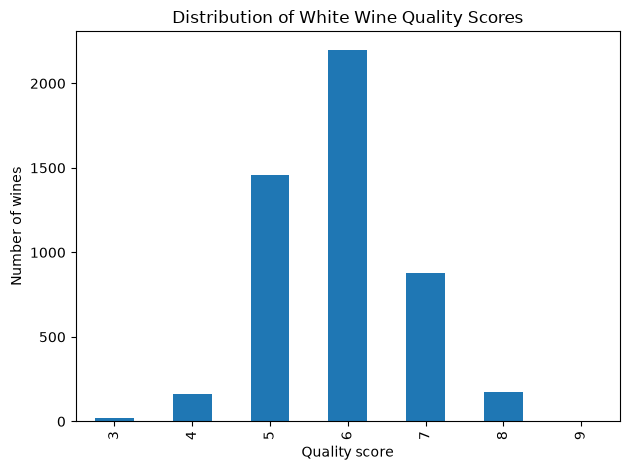

In [36]:
import matplotlib.pyplot as plt

df["quality"].value_counts().sort_index().plot(
    kind="bar",
    xlabel="Quality score",
    ylabel="Number of wines",
    title="Distribution of White Wine Quality Scores",
)

plt.tight_layout()
plt.show()

In [37]:
df.shape, df.drop_duplicates().shape

((4898, 12), (3961, 12))

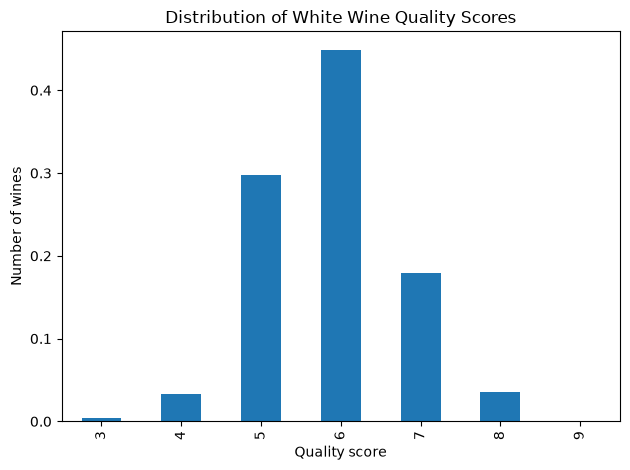

In [38]:


df["quality"].value_counts(normalize=True).sort_index().plot(
    kind="bar",
    xlabel="Quality score",
    ylabel="Number of wines",
    title="Distribution of White Wine Quality Scores",
)

plt.tight_layout()
plt.show()

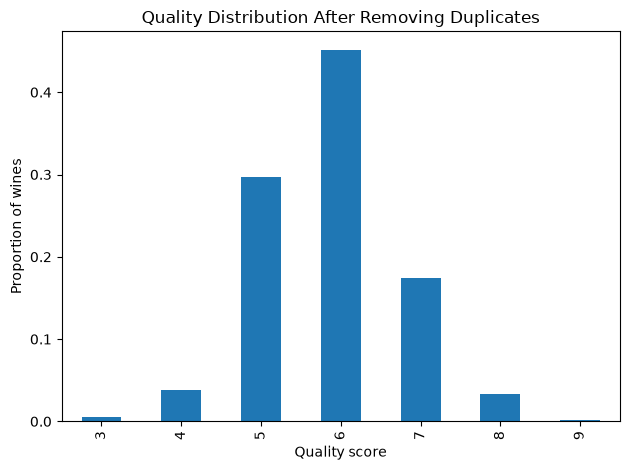

In [39]:
df.drop_duplicates()["quality"].value_counts(normalize=True).sort_index().plot(
    kind="bar",
    xlabel="Quality score",
    ylabel="Proportion of wines",
    title="Quality Distribution After Removing Duplicates"
)

plt.tight_layout()
plt.show()

In [40]:
original_dataset = df["quality"].value_counts(normalize=True).sort_index()

In [41]:
deduplicated_dataset = df.drop_duplicates()["quality"].value_counts(normalize=True).sort_index()

In [42]:
duplicate_values = original_dataset - deduplicated_dataset

In [43]:
duplicate_values

quality
3   -0.000966
4   -0.005348
5    0.000826
6   -0.002647
7    0.005719
8    0.002656
9   -0.000241
Name: proportion, dtype: float64

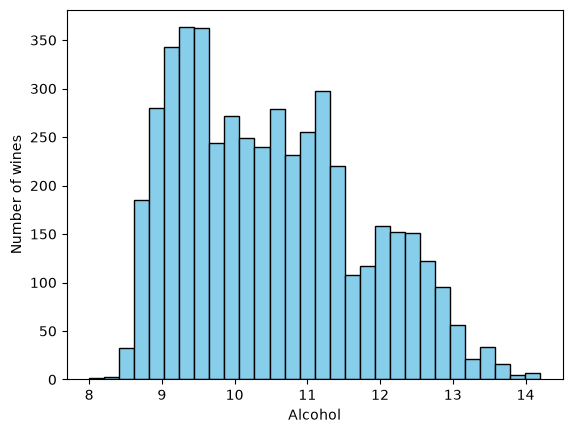

In [44]:
plt.hist(df["alcohol"], bins=30, color="skyblue", edgecolor="black")
plt.xlabel("Alcohol")
plt.ylabel("Number of wines")
plt.show()

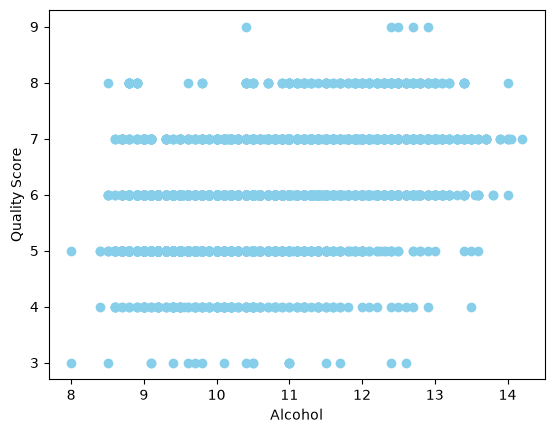

In [45]:
plt.scatter(df["alcohol"], df["quality"], color="skyblue", marker="o")
plt.xlabel("Alcohol")
plt.ylabel("Quality Score")
plt.show()

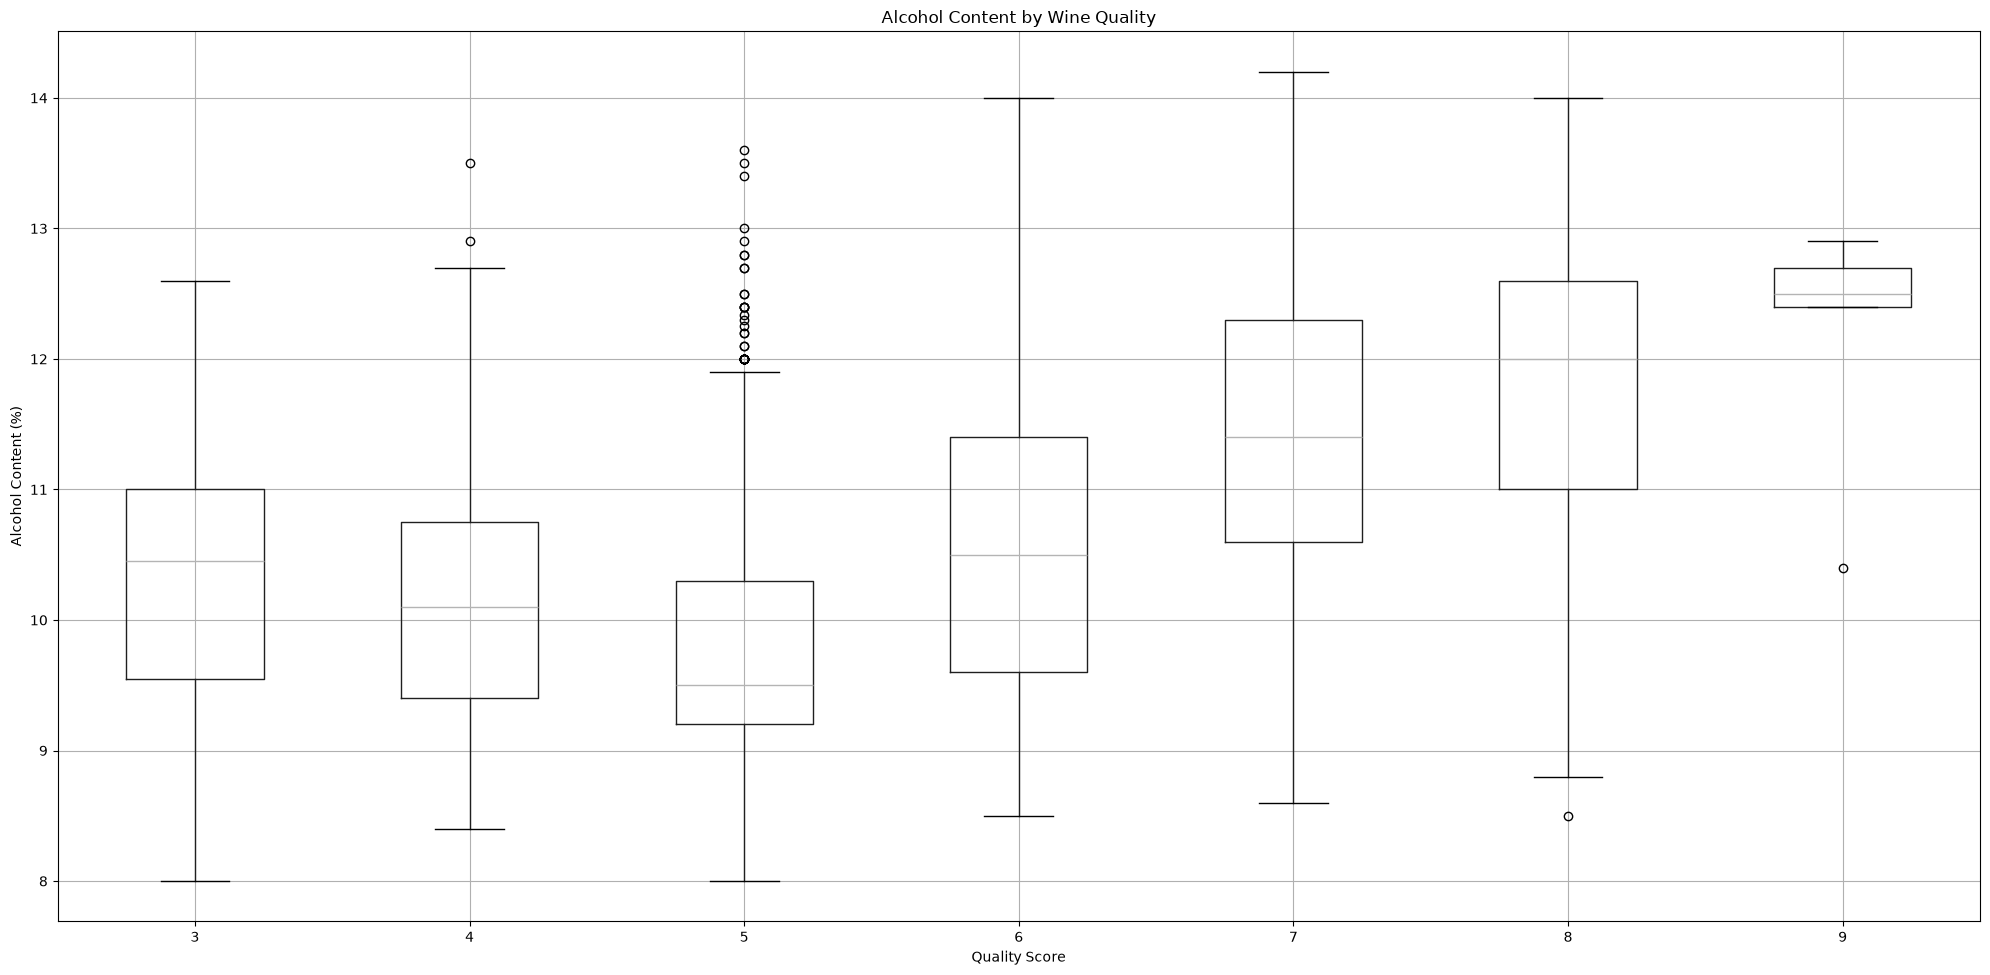

In [46]:
df.boxplot(column="alcohol", by="quality", figsize=(20, 10))
plt.title("Alcohol Content by Wine Quality")
plt.suptitle("")
plt.xlabel("Quality Score")
plt.ylabel("Alcohol Content (%)")
plt.tight_layout()
plt.show()

In [47]:
corr_mat = df["alcohol"].corr(df["quality"])
print(corr_mat)

0.43557471546137294


In [48]:
corr_matrix_all = df.corr(numeric_only=True)
quality_corr = corr_matrix_all["quality"].sort_index(ascending=False)
print(quality_corr)

volatile acidity       -0.194723
total sulfur dioxide   -0.174737
sulphates               0.053678
residual sugar         -0.097577
quality                 1.000000
pH                      0.099427
free sulfur dioxide     0.008158
fixed acidity          -0.113663
density                -0.307123
citric acid            -0.009209
chlorides              -0.209934
alcohol                 0.435575
Name: quality, dtype: float64


<Axes: >

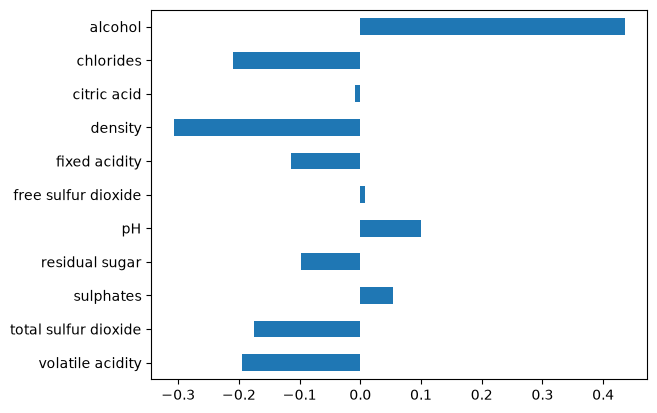

In [49]:
corr_graph = quality_corr.drop("quality")
corr_graph.plot(kind="barh")

In [56]:
print(df.columns.tolist())

['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'quality']


In [58]:
X = df.drop(columns=["quality"])
y = df["quality"]

In [59]:
print(X.shape)
print(y.shape)

(4898, 11)
(4898,)


In [62]:
from sklearn.model_selection import train_test_split

In [68]:
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42, test_size=0.20)

In [69]:
print(X_train.shape)
print(y_train.shape)
print(X_test.shape)
print(y_test.shape)

(3918, 11)
(3918,)
(980, 11)
(980,)


In [70]:
from sklearn.linear_model import LinearRegression

In [71]:
model = LinearRegression()
model.fit(X_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](11,)","[ 0.05,-1.91,-0.06,..., 0.6 , 0.65, 0.23]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](11,)","['fixed acidity','volatile acidity','citric acid',...,'pH','sulphates', 'alcohol']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,124.4
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,11
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(11)


In [74]:
y_pred = model.predict(X_test)

In [76]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import math

In [84]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
r2score = r2_score(y_test, y_pred)

print("MAE : ", mae)
print("RMSE : ", math.sqrt(mse))
print("R2 Score : ", r2score)



MAE :  0.586266538325047
RMSE :  0.7543373063311434
R2 Score :  0.26527500421791583


In [85]:
mean_quality = y_train.mean()
baseline_pred = np.full(len(y_test), mean_quality)

print("Mean:", mean_quality)
print("First 5 predictions:", baseline_pred[:5])

Mean: 5.871362940275651
First 5 predictions: [5.87136294 5.87136294 5.87136294 5.87136294 5.87136294]


In [86]:
baseline_mae = mean_absolute_error(y_test, baseline_pred)
baseline_rmse = np.sqrt(mean_squared_error(y_test, baseline_pred))
baseline_r2 = r2_score(y_test, baseline_pred)

print("Baseline MAE:", baseline_mae)
print("Baseline RMSE:", baseline_rmse)
print("Baseline R2:", baseline_r2)

Baseline MAE: 0.6749789042722756
Baseline RMSE: 0.8806495608493429
Baseline R2: -0.0013822465633210879


In [87]:
print("Training target mean:", y_train.mean())
print("Training target range:", y_train.min(), "to", y_train.max())

print("Test target range:", y_test.min(), "to", y_test.max())
print("First 5 baseline predictions:", baseline_pred[:5])

Training target mean: 5.871362940275651
Training target range: 3 to 9
Test target range: 3 to 8
First 5 baseline predictions: [5.87136294 5.87136294 5.87136294 5.87136294 5.87136294]
